In [8]:
library(tidyverse)

#Import dataset
wine <- read_csv("winequality-red.csv")

head(wine)

Rows: 1599 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (12): fixed acidity, volatile acidity, citric acid, residual sugar, chlo...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
7.8,0.88,0.00,2.6,0.098,25,67,0.9968,3.20,0.68,9.8,5
7.8,0.76,0.04,2.3,0.092,15,54,0.9970,3.26,0.65,9.8,5
11.2,0.28,0.56,1.9,0.075,17,60,0.9980,3.16,0.58,9.8,6
7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
7.4,0.66,0.00,1.8,0.075,13,40,0.9978,3.51,0.56,9.4,5


## Cleaning the Data

In [9]:
library(janitor)

wine <- wine |>
  clean_names()

names(wine)

[1] "fixed_acidity"        "volatile_acidity"     "citric_acid"         
 [4] "residual_sugar"       "chlorides"            "free_sulfur_dioxide" 
 [7] "total_sulfur_dioxide" "density"              "p_h"                 
[10] "sulphates"            "alcohol"              "quality"

In [10]:
#Count missing values in each column
colSums(is.na(wine))

#Total missing values
sum(is.na(wine))

fixed_acidity     volatile_acidity          citric_acid 
                   0                    0                    0 
      residual_sugar            chlorides  free_sulfur_dioxide 
                   0                    0                    0 
total_sulfur_dioxide              density                  p_h 
                   0                    0                    0 
           sulphates              alcohol              quality 
                   0                    0                    0

[1] 0

## Exploratory Data Analysis

### Summary Statistics for All Variables

In [11]:
#Dataset dimensions
dim(wine)

#Summary statistics
summary(wine)

[1] 1599   12

 fixed_acidity   volatile_acidity  citric_acid    residual_sugar  
 Min.   : 4.60   Min.   :0.1200   Min.   :0.000   Min.   : 0.900  
 1st Qu.: 7.10   1st Qu.:0.3900   1st Qu.:0.090   1st Qu.: 1.900  
 Median : 7.90   Median :0.5200   Median :0.260   Median : 2.200  
 Mean   : 8.32   Mean   :0.5278   Mean   :0.271   Mean   : 2.539  
 3rd Qu.: 9.20   3rd Qu.:0.6400   3rd Qu.:0.420   3rd Qu.: 2.600  
 Max.   :15.90   Max.   :1.5800   Max.   :1.000   Max.   :15.500  
   chlorides       free_sulfur_dioxide total_sulfur_dioxide    density      
 Min.   :0.01200   Min.   : 1.00       Min.   :  6.00       Min.   :0.9901  
 1st Qu.:0.07000   1st Qu.: 7.00       1st Qu.: 22.00       1st Qu.:0.9956  
 Median :0.07900   Median :14.00       Median : 38.00       Median :0.9968  
 Mean   :0.08747   Mean   :15.87       Mean   : 46.47       Mean   :0.9967  
 3rd Qu.:0.09000   3rd Qu.:21.00       3rd Qu.: 62.00       3rd Qu.:0.9978  
 Max.   :0.61100   Max.   :72.00       Max.   :289.00       Max.   :1

### Distribution of Wine Quality

quality,n,percentage
<dbl>,<int>,<dbl>
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


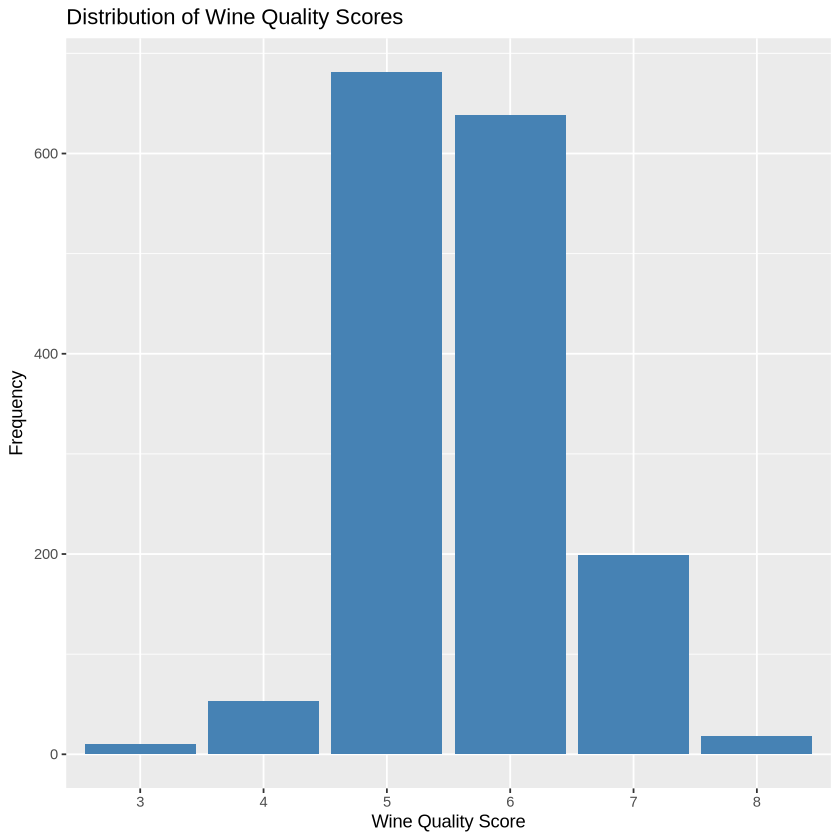

In [25]:
wine |>
  count(quality) |>
  mutate(percentage = round(n / sum(n) * 100, 2))

ggplot(wine, aes(x = factor(quality))) +
  geom_bar(fill = "steelblue") +
  labs(title = "Distribution of Wine Quality Scores",
    x = "Wine Quality Score",
    y = "Frequency")

### Distribution of Input Variables (Wine Characteristics)

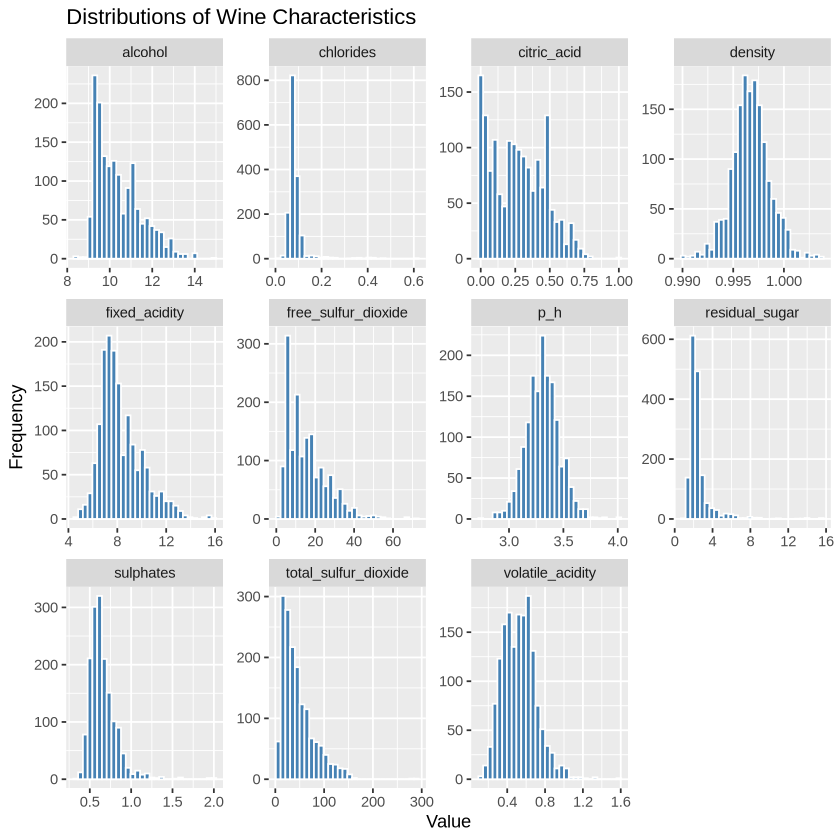

In [15]:
wine |>
  select(-quality) |>
  pivot_longer(cols = everything(),
    names_to = "variable",
    values_to = "value") |>
  ggplot(aes(x = value)) +
  geom_histogram(bins = 30,
    fill = "steelblue",
    color = "white") +
  facet_wrap(~ variable, scales = "free") +
  labs(title = "Distributions of Wine Characteristics",
    x = "Value",
    y = "Frequency") 

### Examining Some Selected Correlation Coeffecients (Pearson)

In [23]:
#Correlation between alcohol and quality
cor(wine$alcohol, wine$quality)

#Correlation between volatile acidity and quality
cor(wine$volatile_acidity, wine$quality)

#Correlation between sulphates and quality
cor(wine$sulphates, wine$quality)

[1] 0.4761663

[1] -0.3905578

[1] 0.2513971

### Creating a Correlation Plot/ HeatMap for all Wine Characteristics

Installing package into ‘/home/jupyter/R/x86_64-pc-linux-gnu-library/4.5’
(as ‘lib’ is unspecified)



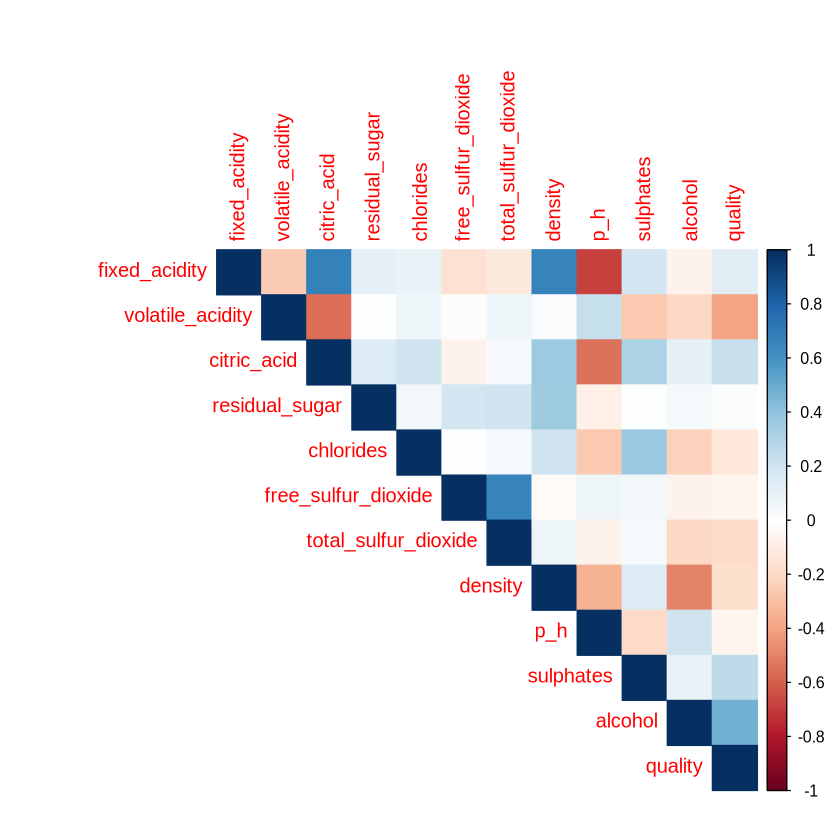

In [24]:
install.packages("corrplot")   
library(corrplot)

cor_matrix <- cor(wine)

corrplot(cor_matrix,
         method = "color",
         type = "upper")